# Handwritten Digit Recognizer — CNN on MNIST

**Goal:** train a Convolutional Neural Network that classifies 28×28 grayscale images of handwritten digits (0–9).

**Dataset:** Kaggle *Digit Recognizer* (MNIST in CSV form) — https://www.kaggle.com/c/digit-recognizer
`train.csv` has 42,000 labelled images (a `label` column + 784 pixel columns); `test.csv` has 28,000 unlabelled images.

**Approach**
1. Load and preprocess the data
2. Explore it
3. Build a simple baseline (Logistic Regression) to have something to beat
4. Build and train a CNN (with dropout)
5. Evaluate: accuracy, confusion matrix, misclassified digits, error analysis
6. Predict the Kaggle test set and save the model

## 1. Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

EPOCHS = 3
BATCH_SIZE = 256

os.makedirs("outputs", exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Load the data
The script looks for the CSVs in the current folder, `./data`, or the Kaggle input folder.

In [2]:
def find_file(name):
    for path in [name, os.path.join("data", name),
                 os.path.join("/kaggle/input/digit-recognizer", name)]:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"{name} not found. Download it from "
                            "https://www.kaggle.com/c/digit-recognizer")

train_df = pd.read_csv(find_file("train.csv"))
test_df = pd.read_csv(find_file("test.csv"))
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Missing values in train:", int(train_df.isna().sum().sum()))
train_df.head()

Train: (42000, 785) | Test: (28000, 784)
Missing values in train: 0


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Preprocess
- **Scale pixels to 0–1** (divide by 255). Neural networks train faster and more stably on small, consistent input ranges.
- **Reshape to (28, 28, 1)** — Conv2D layers expect `height × width × channels`; grayscale has 1 channel.
- **90/10 stratified split** — keeps the digit proportions equal in the training and validation sets, so the validation score is a fair estimate of performance on unseen data.

In [3]:
y = train_df["label"].values
X = (train_df.drop(columns="label").values / 255.0).astype("float32").reshape(-1, 28, 28, 1)
X_test = (test_df.values / 255.0).astype("float32").reshape(-1, 28, 28, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train: (37800, 28, 28, 1) | Validation: (4200, 28, 28, 1) | Test: (28000, 28, 28, 1)


## 4. Explore the data

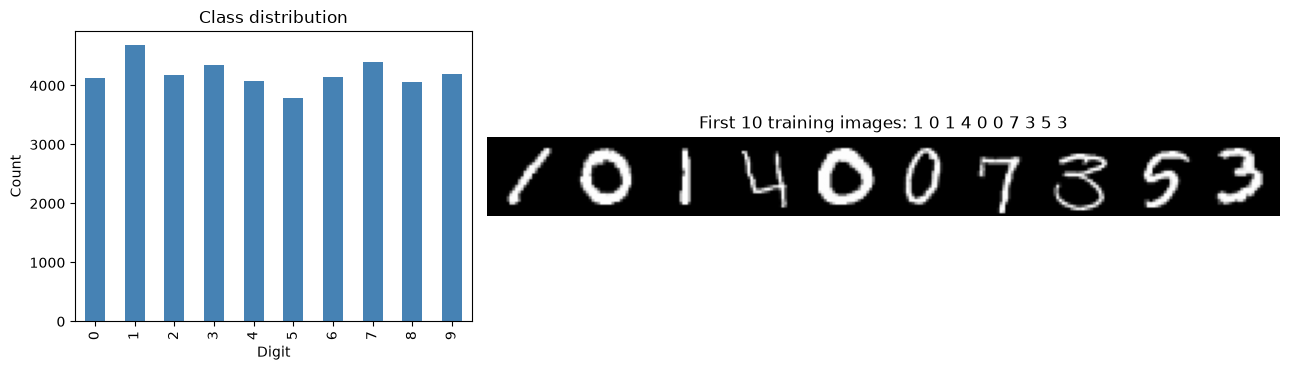

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2]})
pd.Series(y).value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Class distribution"); axes[0].set_xlabel("Digit"); axes[0].set_ylabel("Count")

grid = np.hstack([X[i].squeeze() for i in range(10)])
axes[1].imshow(grid, cmap="gray"); axes[1].axis("off")
axes[1].set_title("First 10 training images: " + " ".join(str(v) for v in y[:10]))
plt.tight_layout(); plt.savefig("outputs/eda.png", dpi=120); plt.show()

**Observation:** the classes are roughly balanced (about 9–11% each), so plain accuracy is a reasonable metric here — unlike an imbalanced problem such as churn prediction.

## 5. Baseline: Logistic Regression
Before building a CNN, we need a reference point. Logistic Regression (trained on a 5,000-image subset for speed) treats each image as a flat vector of 784 numbers, so it **ignores the 2-D spatial structure** of the image. If the CNN is worth the extra complexity, it should clearly beat this.

In [5]:
n = min(5000, len(X_train))
lr = LogisticRegression(max_iter=20)
lr.fit(X_train[:n].reshape(n, -1), y_train[:n])
baseline_acc = accuracy_score(y_val, lr.predict(X_val.reshape(len(X_val), -1)))
print(f"Baseline (Logistic Regression) validation accuracy: {baseline_acc:.4f}")

Baseline (Logistic Regression) validation accuracy: 0.8981


## 6. CNN model
| Layer | Purpose |
|---|---|
| `Conv2D` (16, then 32 filters, 3×3) | Learns local patterns — edges and strokes in the first layer, loops and curves in the second |
| `MaxPooling2D` | Halves the spatial size and gives small translation tolerance |
| `Dropout` (0.3) | Randomly switches off neurons during training to reduce overfitting |
| `Flatten` + `Dense(64)` | Combines the learned features |
| `Dense(10, softmax)` | Outputs a probability for each digit 0–9 |

The model is deliberately small so it trains in about a minute on a laptop CPU.

In [6]:
def build_model():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def get_callbacks():
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ]

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 16)          │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          51,264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train

In [7]:
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE,
                    callbacks=get_callbacks(), verbose=2)

Epoch 1/3
148/148 - 8s - 52ms/step - accuracy: 0.8116 - loss: 0.6452 - val_accuracy: 0.9457 - val_loss: 0.1748 - learning_rate: 0.0010
Epoch 2/3
148/148 - 6s - 41ms/step - accuracy: 0.9504 - loss: 0.1628 - val_accuracy: 0.9679 - val_loss: 0.1088 - learning_rate: 0.0010
Epoch 3/3
148/148 - 7s - 44ms/step - accuracy: 0.9640 - loss: 0.1149 - val_accuracy: 0.9755 - val_loss: 0.0793 - learning_rate: 0.0010


## 8. Evaluate

CNN validation accuracy: 0.9755 | loss: 0.0793


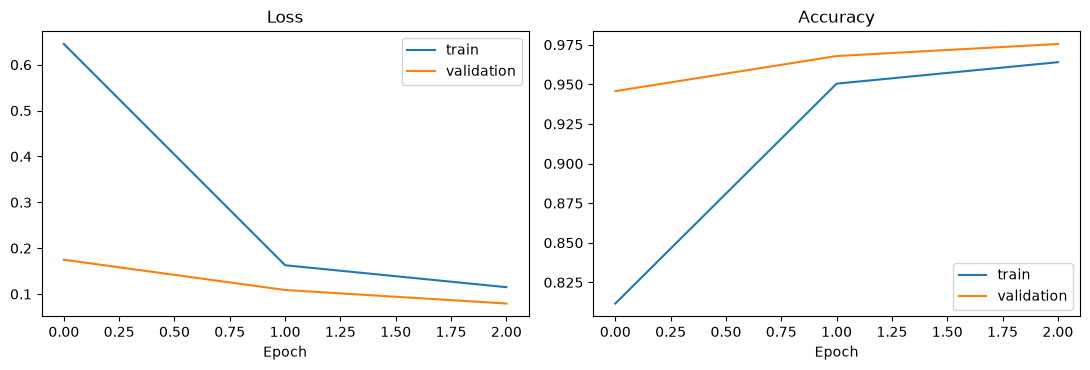

In [8]:
val_loss, cnn_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"CNN validation accuracy: {cnn_acc:.4f} | loss: {val_loss:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(history.history[key], label="train")
    ax.plot(history.history["val_" + key], label="validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig("outputs/training_curves.png", dpi=120); plt.show()

**Reading the curves:** validation accuracy tracking (or slightly exceeding) training accuracy is expected, because dropout makes training harder than validation. A large, growing gap between the two would signal overfitting.

              precision    recall  f1-score   support

           0     0.9901    0.9685    0.9792       413
           1     0.9915    0.9979    0.9947       468
           2     0.9515    0.9856    0.9683       418
           3     0.9858    0.9586    0.9720       435
           4     0.9926    0.9828    0.9877       407
           5     0.9634    0.9684    0.9659       380
           6     0.9810    0.9976    0.9892       414
           7     0.9817    0.9750    0.9783       440
           8     0.9624    0.9458    0.9540       406
           9     0.9532    0.9714    0.9622       419

    accuracy                         0.9755      4200
   macro avg     0.9753    0.9752    0.9751      4200
weighted avg     0.9756    0.9755    0.9755      4200



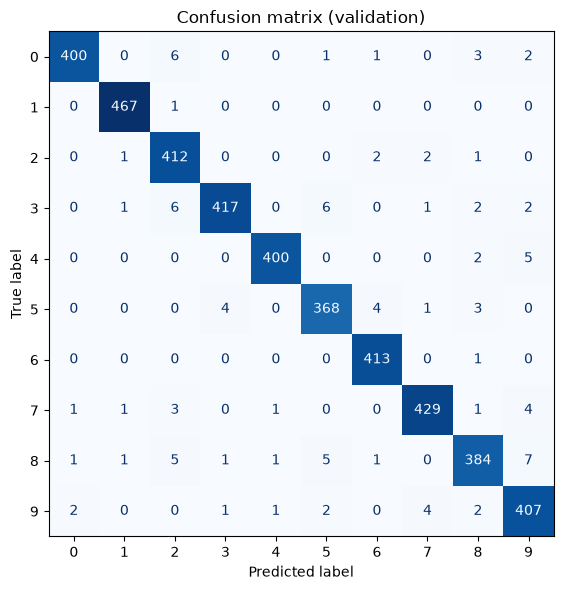

In [9]:
val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
print(classification_report(y_val, val_pred, digits=4))

cm = confusion_matrix(y_val, val_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix (validation)")
plt.tight_layout(); plt.savefig("outputs/confusion_matrix.png", dpi=120); plt.show()

### Misclassified digits

Misclassified: 103 of 4200


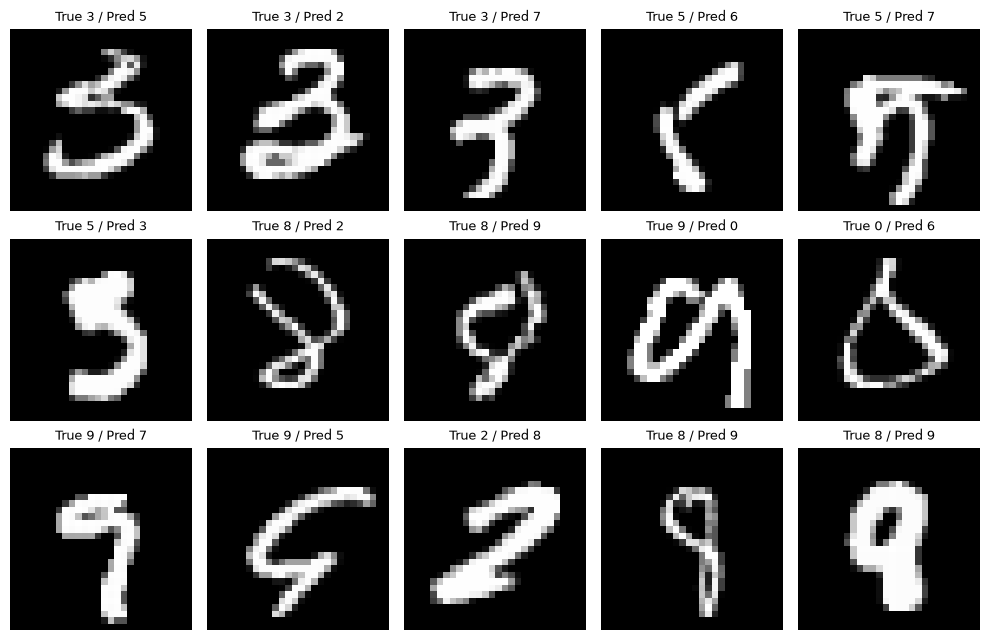

In [10]:
wrong = np.where(val_pred != y_val)[0]
print(f"Misclassified: {len(wrong)} of {len(y_val)}")

fig, axes = plt.subplots(3, 5, figsize=(10, 6.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, idx in zip(axes.ravel(), wrong[:15]):
    ax.imshow(X_val[idx].squeeze(), cmap="gray")
    ax.set_title(f"True {y_val[idx]} / Pred {val_pred[idx]}", fontsize=9)
plt.tight_layout(); plt.savefig("outputs/misclassified.png", dpi=120); plt.show()

### Error analysis: which digits get confused most?

In [11]:
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted([(i, j, off[i, j]) for i in range(10) for j in range(10) if off[i, j] > 0],
               key=lambda t: -t[2])
pd.DataFrame(pairs[:5], columns=["True digit", "Predicted as", "Count"])

,True digit,Predicted as,Count
0,8,9,7
1,0,2,6
2,3,2,6
3,3,5,6
4,4,9,5


**Observation:** the remaining errors are usually between digits with similar shapes (for example 4 vs 9, 3 vs 5, 7 vs 1) or images that are sloppy or ambiguous even to a human reader (see the plot above).

## 9. Model comparison

In [12]:
results = pd.DataFrame({
    "Model": ["Logistic Regression (baseline)", "CNN"],
    "Validation accuracy": [baseline_acc, cnn_acc],
}).round(4)
results

,Model,Validation accuracy
0,Logistic Regression (baseline),0.8981
1,CNN,0.9755


## 10. Predict a single image (sanity check)

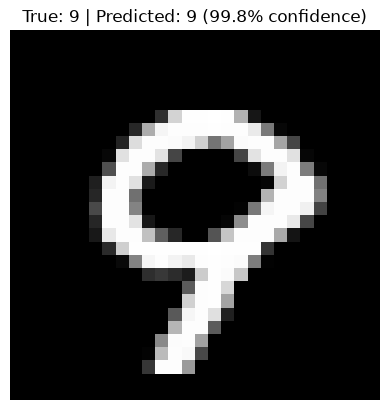

In [13]:
i = np.random.randint(len(X_val))
probs = model.predict(X_val[i:i+1], verbose=0)[0]
plt.imshow(X_val[i].squeeze(), cmap="gray")
plt.title(f"True: {y_val[i]} | Predicted: {probs.argmax()} ({probs.max():.1%} confidence)")
plt.axis("off"); plt.show()

## 11. Predict the Kaggle test set and save the model
`submission.csv` can be uploaded to the Kaggle competition; the saved model is used by the optional demo app (`app.py`).

In [14]:
test_pred = model.predict(X_test, verbose=0).argmax(axis=1)
pd.DataFrame({"ImageId": np.arange(1, len(test_pred) + 1), "Label": test_pred}) \
  .to_csv("submission.csv", index=False)
model.save("mnist_cnn.keras")
print("Saved submission.csv and mnist_cnn.keras")

Saved submission.csv and mnist_cnn.keras


## 12. Conclusion
- The CNN clearly outperforms the Logistic Regression baseline, because convolutions exploit the 2-D structure of the image that a flat model ignores.
- Dropout keeps the gap between training and validation performance small.
- Remaining errors are mostly visually similar digit pairs or ambiguous handwriting.

**Possible improvements:** add data augmentation, Batch Normalization, more epochs, or an ensemble of several CNNs.